# RQ3: Do rewriters leave a fingerprint? Paraphrasers vs translators

**Question.** Given a rewritten English text (T1, T2 or T3), can a classifier tell *which model* produced it? Samer's RQ3 asked this for three round-trip translators (MADLAD-400-3B, NLLB-200-1.3B, Qwen3-4B). This notebook asks it for the four English paraphrasers (ChatGPT, PaLM, Dipper, Pegasus) and compares the two.

**Protocol: Samer's RQ3, reproduced** (`pilot.attribution`; the same code reproduced his RQ2 predictions 100%):
- **Inputs:** only the rewritten English text, never metadata or source labels.
- **Documents:** his XSum documents that every paraphraser *and* every translator completed (178 documents, 31 articles). His translator predictions are re-scored on the same documents, and both families are balanced: every class contributes the same documents at every round.
- **Folds:** 5 article-grouped folds × 5 shufflings (seed 6120). An article's texts are always on one side, so no test text can be matched to a training text with the same content.
- **Main experiment:** train on pooled T1-T3, evaluate each round. Models:
  - word and character TF-IDF;
  - his 187 stylometric features, with and without sentence-boundary features;
  - a length-only control.
- **Further experiments:** cross-round training, leave-one-source-out, and typography normalisation.

**Comparing the two families.** There are 4 paraphrasers (chance 0.25) but 3 translators (chance 0.33), so raw macro-F1 isn't comparable. Both are also reported on a chance-corrected scale: **(F1 − chance) / (1 − chance)**, where 0 = chance and 1 = perfect identification.

Inputs: `scripts/import_samer_rq1.py --files-only`, `scripts/rq2_attribution.py` (stylometric features), then `scripts/rq3_fingerprint.py` (~10 min).

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from pilot.attribution import confusion, macro_f1, per_class, scores
from pilot.config import ROOT, load_config

warnings.filterwarnings("ignore", category=FutureWarning)
cfg = load_config()
DERIVED = cfg["paths"]["derived"]
OUT = cfg["paths"]["results"] / "rq3_fingerprint"
OUT.mkdir(parents=True, exist_ok=True)
SEED, N_BOOT = cfg["seed"], 1000

PARAPHRASERS = ["chatgpt", "palm", "dipper", "pegasus(full)"]
TRANSLATORS = ["madlad-3b", "nllb", "qwen3-4b"]
LABEL = {"chatgpt": "ChatGPT", "palm": "PaLM", "dipper": "Dipper", "pegasus(full)": "Pegasus",
         "madlad-3b": "MADLAD-400-3B", "nllb": "NLLB-200-1.3B", "qwen3-4b": "Qwen3-4B"}
MODELS = ["tfidf_word", "tfidf_char", "stylometric", "stylometric_no_sentence", "length_only"]
MODEL_NAME = {"tfidf_word": "Word n-grams", "tfidf_char": "Char n-grams", "stylometric": "Stylometric",
              "stylometric_no_sentence": "Stylometric, no sentence feats", "length_only": "Length only",
              "tfidf_char_typography_normalised": "Char n-grams, typography normalised",
              "stylometric_no_typography": "Stylometric, no typography"}
FAMILY_COLOR = {"paraphrase": "#2a78d6", "translation": "#eb6834"}   # categorical slots 1-2
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e1"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 160, "savefig.bbox": "tight", "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "axes.titlecolor": INK,
    "axes.titlesize": 11, "axes.labelsize": 9, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.frameon": False, "legend.fontsize": 8, "font.size": 9,
})

def save(fig, name, table=None):
    fig.savefig(OUT / f"{name}.png")
    if table is not None:
        table.to_csv(OUT / f"{name}.csv", index=False)

def cell(r):
    return f"{r.macro_f1:.3f} [{r.macro_f1_ci_low:.3f}, {r.macro_f1_ci_high:.3f}]"

need = ["rq3_paraphrase_predictions.parquet", "rq3_pool_features.parquet", "samer_rq3_predictions.parquet"]
assert all((DERIVED / f).exists() for f in need), "run scripts/import_samer_rq1.py --files-only, then scripts/rq3_fingerprint.py"
pp = pd.read_parquet(DERIVED / "rq3_paraphrase_predictions.parquet")
pool = pd.read_parquet(DERIVED / "rq3_pool_features.parquet")
COHORT = set(pool.item_id)
tp = pd.read_parquet(DERIVED / "samer_rq3_predictions.parquet")
tp = tp[tp.item_id.isin(COHORT)].rename(columns={"translator": "rewriter"})
assert tp.item_id.nunique() == len(COHORT), "Samer's predictions don't cover the cohort"
main_p = pp[pp.experiment == "main"].assign(family="paraphrase")
main_t = tp.assign(family="translation")
print(f"cohort: {len(COHORT)} documents, {pool.article_id.nunique()} articles | paraphrase texts: {len(pool):,} "
      f"| translator texts: {tp.text_id.nunique():,}")
display(pool.groupby(["stage", "rewriter"]).size().unstack()[PARAPHRASERS].rename(columns=LABEL)
        .rename_axis(index="paraphrase texts per round"))

cohort: 178 documents, 31 articles | paraphrase texts: 2,136 | translator texts: 1,602


rewriter,ChatGPT,PaLM,Dipper,Pegasus
paraphrase texts per round,,,,
T1,178,178,178,178
T2,178,178,178,178
T3,178,178,178,178


## 1. Main experiment: how identifiable is each family?

Models are trained on pooled T1-T3 and evaluated per round and pooled. Samer's translator classifiers were trained on his 193 matched documents and are scored here on the 178 shared ones. The paraphrase classifiers are trained on the 178. This small difference in training size, if anything, favours the translators.

Raw macro-F1 [95% CI] (chance: paraphrase 0.25, translation 0.333):
Chance-corrected difference, paraphrase - translation, pooled T1-T3 (paired article bootstrap):


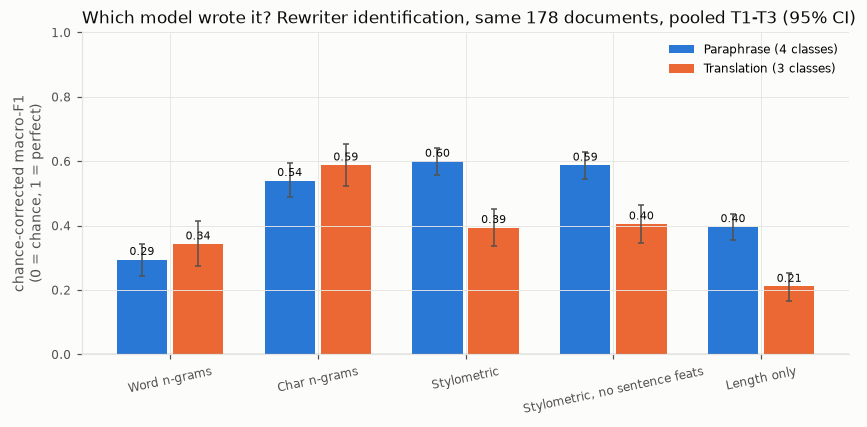

stage                                                         T1  \
family      model                                                  
paraphrase  Word n-grams                    0.429 [0.384, 0.471]   
            Char n-grams                    0.631 [0.586, 0.676]   
            Stylometric                     0.669 [0.630, 0.709]   
            Stylometric, no sentence feats  0.659 [0.622, 0.697]   
            Length only                     0.511 [0.477, 0.543]   
translation Word n-grams                    0.544 [0.499, 0.588]   
            Char n-grams                    0.718 [0.668, 0.762]   
            Stylometric                     0.580 [0.541, 0.617]   
            Stylometric, no sentence feats  0.590 [0.551, 0.631]   
            Length only                     0.450 [0.418, 0.476]   

stage                                                         T2  \
family      model                                                  
paraphrase  Word n-grams                    0.477 [0.439, 0.513]   
            Char n-grams                    0.662 [0.619, 0.708]   
            Stylometric                     0.701 [0.666, 0.735]   
            Stylometric, no sentence feats  0.692 [0.655, 0.727]   
            Length only                     0.556 [0.524, 0.589]   
translation Word n-grams                    0.566 [0.515, 0.614]   
            Char n-grams                    0.727 [0.680, 0.770]   
            Stylometric                     0.601 [0.559, 0.639]   
            Stylometric, no sentence feats  0.609 [0.570, 0.650]   
            Length only                     0.474 [0.445, 0.505]   

stage                                                         T3  \
family      model                                                  
paraphrase  Word n-grams                    0.503 [0.465, 0.542]   
            Char n-grams                    0.670 [0.630, 0.711]   
            Stylometric                     0.728 [0.696, 0.760]   
            Stylometric, no sentence feats  0.720 [0.685, 0.753]   
            Length only                     0.573 [0.535, 0.607]   
translation Word n-grams                    0.575 [0.524, 0.623]   
            Char n-grams                    0.732 [0.688, 0.777]   
            Stylometric                     0.605 [0.559, 0.649]   
            Stylometric, no sentence feats  0.611 [0.565, 0.651]   
            Length only                     0.497 [0.462, 0.532]   

stage                                                      T1-T3  
family      model                                                 
paraphrase  Word n-grams                    0.471 [0.433, 0.508]  
            Char n-grams                    0.655 [0.616, 0.695]  
            Stylometric                     0.700 [0.667, 0.731]  
            Stylometric, no sentence feats  0.691 [0.658, 0.721]  
            Length only                     0.547 [0.516, 0.577]  
translation Word n-grams                    0.562 [0.515, 0.609]  
            Char n-grams                    0.725 [0.682, 0.769]  
            Stylometric                     0.596 [0.557, 0.635]  
            Stylometric, no sentence feats  0.603 [0.564, 0.643]  
            Length only                     0.474 [0.443, 0.502]

,model,paraphrase_corrected,translation_corrected,difference,ci_low,ci_high
0,Word n-grams,0.295,0.343,-0.048,-0.124,0.028
1,Char n-grams,0.540,0.588,-0.048,-0.104,0.009
2,Stylometric,0.600,0.394,0.206,0.152,0.257
3,"Stylometric, no sentence feats",0.588,0.405,0.183,0.130,0.247
4,Length only,0.397,0.211,0.185,0.141,0.231


In [5]:
# 1.1 Scores per family, model and round; chance-corrected comparison with a paired article bootstrap
def fam_scores(p, labels, fam):
    k = len(labels)
    s = pd.concat([scores(p, ["model", "stage"], labels, n_boot=N_BOOT, seed=SEED),
                   scores(p, ["model"], labels, n_boot=N_BOOT, seed=SEED).assign(stage="T1-T3")], ignore_index=True)
    for c in ("macro_f1", "macro_f1_ci_low", "macro_f1_ci_high"):
        s[c.replace("macro_f1", "corrected")] = (s[c] - 1 / k) / (1 - 1 / k)
    return s.assign(family=fam, k=k)

sp = fam_scores(main_p, PARAPHRASERS, "paraphrase")
st = fam_scores(main_t, TRANSLATORS, "translation")
both = pd.concat([sp, st], ignore_index=True)
both.to_csv(OUT / "scores_main.csv", index=False)

# Paired bootstrap of the chance-corrected difference (paraphrase - translation), pooled T1-T3:
# the same articles are resampled for both families
rng = np.random.default_rng(SEED)
arts = sorted(set(main_p.article_id))
diff_rows = []
for m in MODELS:
    P, T = main_p[main_p.model == m], main_t[main_t.model == m]
    ip = {a: np.flatnonzero(P.article_id.to_numpy() == a) for a in arts}
    it = {a: np.flatnonzero(T.article_id.to_numpy() == a) for a in arts}
    ptp, ppp, ttp, tpp = P.y_true.to_numpy(), P.y_pred.to_numpy(), T.y_true.to_numpy(), T.y_pred.to_numpy()
    corr = lambda f, k: (f - 1 / k) / (1 - 1 / k)   # noqa: E731
    d0 = corr(macro_f1(ptp, ppp, PARAPHRASERS), 4) - corr(macro_f1(ttp, tpp, TRANSLATORS), 3)
    boots = []
    for _ in range(N_BOOT):
        pick = rng.choice(arts, len(arts), replace=True)
        sp_, st_ = np.concatenate([ip[a] for a in pick]), np.concatenate([it[a] for a in pick])
        boots.append(corr(macro_f1(ptp[sp_], ppp[sp_], PARAPHRASERS), 4) - corr(macro_f1(ttp[st_], tpp[st_], TRANSLATORS), 3))
    diff_rows.append({"model": m, "paraphrase_corrected": corr(macro_f1(ptp, ppp, PARAPHRASERS), 4),
                      "translation_corrected": corr(macro_f1(ttp, tpp, TRANSLATORS), 3), "difference": d0,
                      "ci_low": np.percentile(boots, 2.5), "ci_high": np.percentile(boots, 97.5)})
diff = pd.DataFrame(diff_rows)
diff.round(4).to_csv(OUT / "family_difference.csv", index=False)

# Figure: chance-corrected identifiability per model, paraphrase vs translation (pooled T1-T3)
g = both[both.stage == "T1-T3"].set_index(["family", "model"])
fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(MODELS))
for i, fam in enumerate(["paraphrase", "translation"]):
    v = g.loc[fam].reindex(MODELS)
    xs = x + (i - 0.5) * 0.38
    ax.bar(xs, v.corrected, width=0.34, color=FAMILY_COLOR[fam],
           label=f"{fam.capitalize()} ({4 if fam == 'paraphrase' else 3} classes)")
    ax.errorbar(xs, v.corrected, yerr=[v.corrected - v.corrected_ci_low, v.corrected_ci_high - v.corrected],
                fmt="none", ecolor=MUTED, capsize=2, lw=1)
    for xi, yi in zip(xs, v.corrected):
        ax.annotate(f"{yi:.2f}", (xi, yi), xytext=(0, 3), textcoords="offset points", ha="center", fontsize=7, color=INK)
ax.axhline(0, color=MUTED, lw=0.8)
ax.set_xticks(x, [MODEL_NAME[m] for m in MODELS], rotation=12)
ax.set_ylabel("chance-corrected macro-F1\n(0 = chance, 1 = perfect)"); ax.set_ylim(0, 1)
ax.legend(loc="upper right")
ax.set_title(f"Which model wrote it? Rewriter identification, same {len(COHORT)} documents, pooled T1-T3 (95% CI)",
             loc="left")
save(fig, "identifiability_by_family")
plt.show()

t = both.copy()
t["cell"] = t.apply(cell, axis=1)
print("Raw macro-F1 [95% CI] (chance: paraphrase 0.25, translation 0.333):")
display(t.pivot_table(index=["family", "model"], columns="stage", values="cell", aggfunc="first")
        .reindex([(f, m) for f in ("paraphrase", "translation") for m in MODELS])[["T1", "T2", "T3", "T1-T3"]]
        .rename(index=MODEL_NAME, level=1))
print("Chance-corrected difference, paraphrase - translation, pooled T1-T3 (paired article bootstrap):")
diff.assign(model=diff.model.map(MODEL_NAME)).round(3)

## 2. Who is confused with whom, and what carries the paraphrase fingerprint?

- **Per class:** per-class F1 and confusion matrices for the paraphrasers, on the best text model and the stylometric model.
- **Descriptives:** length relative to T0 and typography. Samer found that MADLAD inserts curly quotes in 58% of its texts.
- **Feature classes:** the stylometric features most indicative of each paraphraser.

Per-class F1 (pooled T1-T3):
Descriptives by paraphraser and round (word/sentence ratio = relative to the same document's T0):


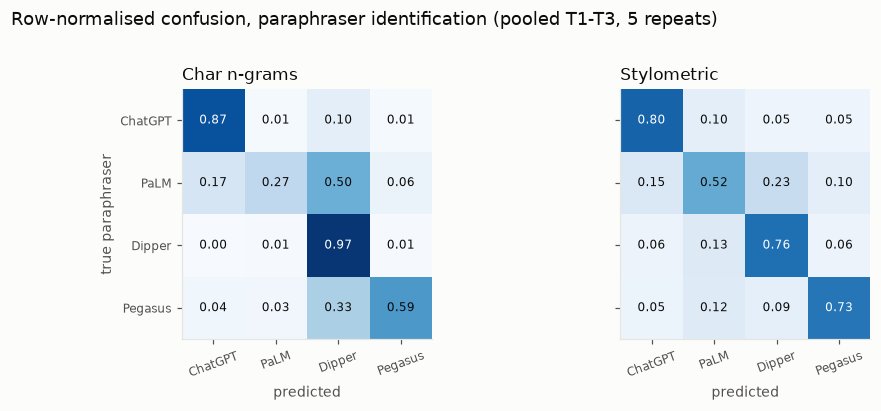

model,Word n-grams,Char n-grams,Stylometric,"Stylometric, no sentence feats",Length only
class,,,,,
ChatGPT,0.841,0.837,0.779,0.782,0.697
PaLM,0.060,0.406,0.554,0.536,0.324
Dipper,0.544,0.670,0.710,0.701,0.545
Pegasus,0.439,0.706,0.756,0.745,0.624


n_words  word_ratio  sentence_ratio  sent_len_mean  \
rewriter stage                                                       
ChatGPT  T1     170.831       0.869           0.890         21.803   
         T2     166.242       0.859           0.879         21.762   
         T3     164.478       0.855           0.884         21.589   
Dipper   T1     203.090       0.914           0.916         22.046   
         T2     183.702       0.834           0.824         22.837   
         T3     166.624       0.771           0.789         22.035   
PaLM     T1     192.371       0.922           0.963         21.090   
         T2     188.517       0.912           0.964         21.016   
         T3     187.253       0.905           0.948         21.168   
Pegasus  T1     184.500       0.805           0.980         17.921   
         T2     164.455       0.711           0.972         15.823   
         T3     155.157       0.668           0.975         14.748   

                comma rate  mattr  share with curly quotes/dashes  
rewriter stage                                                     
ChatGPT  T1          0.053  0.838                           0.000  
         T2          0.052  0.836                           0.000  
         T3          0.053  0.836                           0.000  
Dipper   T1          0.048  0.794                           0.483  
         T2          0.050  0.784                           0.511  
         T3          0.053  0.775                           0.551  
PaLM     T1          0.039  0.827                           0.180  
         T2          0.041  0.825                           0.225  
         T3          0.041  0.823                           0.258  
Pegasus  T1          0.021  0.809                           0.000  
         T2          0.018  0.802                           0.000  
         T3          0.018  0.799                           0.000

In [3]:
# 2.1 Per-class F1, confusion (pooled T1-T3) and descriptives (length vs T0, typography, sentence length, MATTR)
pc = per_class(main_p, ["model"], PARAPHRASERS)
pc.to_csv(OUT / "per_class.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
for ax, m in zip(axes, ["tfidf_char", "stylometric"]):
    cm = confusion(main_p[main_p.model == m], PARAPHRASERS)
    ax.imshow(cm.to_numpy(), cmap="Blues", vmin=0, vmax=1); ax.grid(False)
    ax.set_xticks(range(4), [LABEL[p] for p in PARAPHRASERS], rotation=20)
    ax.set_yticks(range(4), [LABEL[p] for p in PARAPHRASERS] if ax is axes[0] else [""] * 4)
    for i in range(4):
        for j in range(4):
            v = cm.iat[i, j]
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=8, color="white" if v > 0.6 else INK)
    ax.set_title(MODEL_NAME[m], loc="left"); ax.set_xlabel("predicted")
axes[0].set_ylabel("true paraphraser")
fig.suptitle("Row-normalised confusion, paraphraser identification (pooled T1-T3, 5 repeats)", x=0.01, ha="left",
             fontsize=12, color=INK, y=1.02)
fig.tight_layout()
save(fig, "confusion_paraphrasers")
plt.show()

feats = pd.read_parquet(DERIVED / "rq2_features.parquet")
t0w = feats[(feats.variant == "full_text") & feats.text_id.str.endswith("|original|T0")]
t0w = t0w.assign(item_id=t0w.text_id.str.rsplit("|", n=2).str[0]).set_index("item_id")[["n_words", "n_sentences"]]
d = pool.join(t0w, on="item_id", rsuffix="_t0")
d["word_ratio"], d["sentence_ratio"] = d.n_words / d.n_words_t0, d.n_sentences / d.n_sentences_t0
desc = (d.groupby(["rewriter", "stage"])[["n_words", "word_ratio", "sentence_ratio", "sent_len_mean", "punct_01",
                                          "mattr", "has_typography"]].mean()
        .rename(columns={"punct_01": "comma rate", "has_typography": "share with curly quotes/dashes"}))
desc.reset_index().round(4).to_csv(OUT / "length_typography_descriptives.csv", index=False)
print("Per-class F1 (pooled T1-T3):")
display(pc.pivot(index="class", columns="model", values="f1").reindex(PARAPHRASERS)[MODELS]
        .rename(index=LABEL, columns=MODEL_NAME).round(3))
print("Descriptives by paraphraser and round (word/sentence ratio = relative to the same document's T0):")
desc.rename(index=LABEL, level=0).round(3)

## 3. Robustness: cross-round transfer, unseen sources, typography

The same three checks as Samer's RQ3, run on the paraphrasers. His translator results come from his published tables, which use his 193 documents rather than the shared 178. Their predictions weren't published, so these side-by-side numbers are approximate. All scores are also shown chance-corrected.
- **Cross-round:** train on one round, test on every round. Is the fingerprint the same at T1 and T3?
- **Leave one source out:** train without one original source, test on texts from that source. Does the fingerprint transfer to authors the classifier never saw?
- **Typography:** curly quotes, apostrophes and long dashes are normalised to ASCII for the character model, and their rates removed for the stylometric model.

Leave-one-source-out, chance-corrected macro-F1 (translation: Samer's table):
Typography controls, chance-corrected macro-F1 pooled over T1-T3 (translation: Samer's tables, 193 documents):


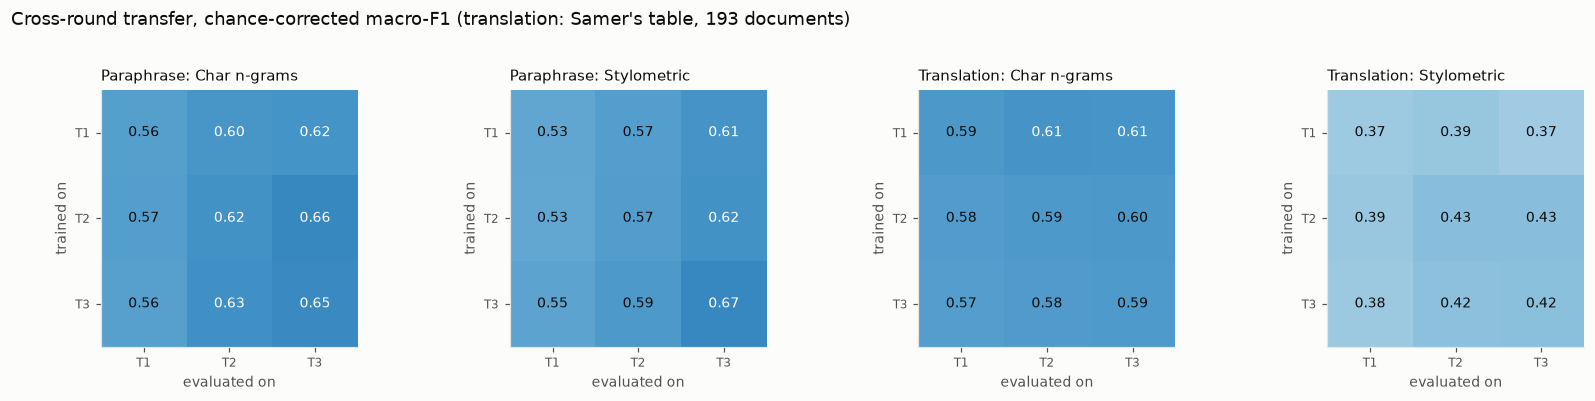

fam              paraphrase              translation             
model           Stylometric Char n-grams Stylometric Char n-grams
held_out_source                                                  
BigScience             0.66         0.51        0.44         0.57
Eleuther-AI            0.49         0.45        0.33         0.64
Human                  0.68         0.62        0.50         0.67
LLAMA                  0.56         0.56        0.44         0.68
OpenAI                 0.39         0.41        0.29         0.33
PaLM                   0.65         0.53        0.32         0.52
Tsinghua               0.61         0.57        0.25         0.53

,control,paraphrase: full,paraphrase: control,translation: full,translation: control
0,"Char n-grams, typography normalised",0.54,0.516,0.595,0.505
1,"Stylometric, no typography",0.60,0.588,0.404,0.330


In [4]:
# 3.1 Cross-round, leave-one-source-out and typography controls (paraphrase), next to Samer's translator tables
SAMER = ROOT.parent / "Samer" / "results" / "rq3"
corr = lambda f, k: (f - 1 / k) / (1 - 1 / k)   # noqa: E731

cr = pp[pp.experiment == "cross_round"]
xs = scores(cr, ["model", "train_stage", "stage"], PARAPHRASERS, n_boot=500, seed=SEED)
xs.to_csv(OUT / "scores_cross_round.csv", index=False)
xs_t = pd.read_csv(SAMER / "scores_cross_round.csv")
fig, axes = plt.subplots(1, 4, figsize=(15, 3.4))
for ax, (fam, s, m) in zip(axes, [("Paraphrase", xs, "tfidf_char"), ("Paraphrase", xs, "stylometric"),
                                  ("Translation", xs_t, "tfidf_char"), ("Translation", xs_t, "stylometric")]):
    k = 4 if fam == "Paraphrase" else 3
    mat = s[s.model == m].pivot(index="train_stage", columns="stage", values="macro_f1").map(lambda f: corr(f, k))
    ax.imshow(mat.to_numpy(), cmap="Blues", vmin=0, vmax=1); ax.grid(False)
    for i in range(3):
        for j in range(3):
            ax.text(j, i, f"{mat.iat[i, j]:.2f}", ha="center", va="center", fontsize=9,
                    color="white" if mat.iat[i, j] > 0.6 else INK)
    ax.set_xticks(range(3), mat.columns); ax.set_yticks(range(3), mat.index)
    ax.set_xlabel("evaluated on"); ax.set_ylabel("trained on")
    ax.set_title(f"{fam}: {MODEL_NAME[m]}", loc="left", fontsize=10)
fig.suptitle("Cross-round transfer, chance-corrected macro-F1 (translation: Samer's table, 193 documents)",
             x=0.01, ha="left", fontsize=12, color=INK, y=1.04)
fig.tight_layout()
save(fig, "cross_round")
plt.show()

lo = scores(pp[pp.experiment == "loso"], ["model", "held_out_source"], PARAPHRASERS, n_boot=300, seed=SEED)
lo.to_csv(OUT / "scores_leave_one_source_out.csv", index=False)
lo_t = pd.read_csv(SAMER / "scores_leave_one_source_out.csv")
lo_tab = pd.concat([lo.assign(fam="paraphrase", c=corr(lo.macro_f1, 4)), lo_t.assign(fam="translation", c=corr(lo_t.macro_f1, 3))])
lo_tab = lo_tab.pivot_table(index="held_out_source", columns=["fam", "model"], values="c")

ty = pp[pp.experiment == "typography"]
ty_s = scores(ty, ["model"], PARAPHRASERS, n_boot=N_BOOT, seed=SEED)
ty_t = pd.read_csv(SAMER / "scores_typography_controls.csv")
ty_t = ty_t[ty_t.stage == "T1-T3"] if (ty_t.stage == "T1-T3").any() else ty_t.groupby("model", as_index=False).macro_f1.mean()
ref_p = both[(both.family == "paraphrase") & (both.stage == "T1-T3")].set_index("model").macro_f1
ty_rows = []
for full, ctrl in [("tfidf_char", "tfidf_char_typography_normalised"), ("stylometric", "stylometric_no_typography")]:
    pc_ = ty_s.set_index("model").macro_f1[ctrl]
    tc_ = ty_t.set_index("model").macro_f1[ctrl]
    tf_ = {"tfidf_char": 0.730, "stylometric": 0.603}[full]   # Samer's pooled main scores (193 documents)
    ty_rows.append({"control": MODEL_NAME[ctrl],
                    "paraphrase: full": corr(ref_p[full], 4), "paraphrase: control": corr(pc_, 4),
                    "translation: full": corr(tf_, 3), "translation: control": corr(tc_, 3)})
ty_tab = pd.DataFrame(ty_rows)
ty_tab.round(4).to_csv(OUT / "typography_controls.csv", index=False)
print("Leave-one-source-out, chance-corrected macro-F1 (translation: Samer's table):")
display(lo_tab.rename(columns=MODEL_NAME, level=1).round(2))
print("Typography controls, chance-corrected macro-F1 pooled over T1-T3 (translation: Samer's tables, 193 documents):")
ty_tab.round(3)

## 4. Interpretation

All results use the same 178 XSum documents and 31 articles with 5×5 article-grouped CV. "Corrected" means (F1 − chance) / (1 − chance): 0 = chance, 1 = perfect.

**1. Both families leave a clear fingerprint, but of different kinds.**
- **Translators are recognised by their wording and characters.** Character n-grams: 0.59 corrected for translators vs 0.54 for paraphrasers. Word n-grams: 0.34 vs 0.29. Neither difference is reliable (CIs include 0).
- **Paraphrasers are recognised by their style and length.** Stylometric features: 0.60 corrected vs 0.39 for translators, difference +0.21 [0.15, 0.26]. Length alone: 0.40 vs 0.21, difference +0.19 [0.14, 0.23].
- **Why:** each paraphraser reshapes the text in its own way.
  - Pegasus shortens it to 67% of its original length by T3, with short sentences (15 words) and the lowest comma rate (0.02 per token vs 0.04-0.05 for the others).
  - Dipper shortens it to 77%, lowers vocabulary diversity (MATTR) and adds curly quotes.
  - ChatGPT trims it to 86% with a stable, comma-rich style.
  - Translators keep length at 92-99%, so they can only be told apart by finer lexical and orthographic choices.

**2. The paraphrase fingerprint gets stronger with every round; the translation fingerprint does not.**
- **Paraphrasers:** identification improves from T1 to T3 (stylometric 0.67 → 0.73 raw macro-F1; char 0.63 → 0.67).
- **Cross-round:** a stylometric model trained and tested on T3 reaches 0.67 corrected, against 0.53 on T1. Each round pushes the text further toward the paraphraser's own style.
- **Translators:** flat from T1 to T3, as in Samer's RQ3, matching their fixed-point behaviour in RQ1.

**3. The paraphrase fingerprint does not rely on typography.**
- **Paraphrasers:** normalising curly quotes and dashes, or removing their rates, barely matters (char 0.54 → 0.52; stylometric 0.60 → 0.59 corrected).
- **Translators:** the same controls cost much more (char 0.60 → 0.51; stylometric 0.40 → 0.33), because MADLAD's curly quotes are a large part of their signal.

**4. It transfers to unseen authors.**
- With one original source held out of training, the paraphraser stylometric model stays at 0.39-0.68 corrected, above the translators' 0.25-0.50 on every source.
- As for translators, held-out OpenAI texts are the hardest. They are the shortest texts, so they carry the least evidence.

**5. Per paraphraser.**
- ChatGPT is the most recognisable (F1 0.84 with char n-grams).
- PaLM is the least: it is often mistaken for Dipper by the char model, and for Dipper or ChatGPT by the stylometric model.
- The stylometric model separates Pegasus and Dipper well (F1 0.71-0.76).

**Link to RQ2.** Paraphrasers erase more of the *original author's* signal (RQ2) and stamp more of *their own* style (RQ3), and both effects grow over rounds. Round-trip translation does the opposite on both counts: it keeps more of the source and adds a mostly lexical and typographic mark that is set in round 1.

## Limitations
- **Small sample:** 31 articles, so CIs are about ±0.04-0.05.
- **Approximate secondary comparisons:** the translator-side cross-round, leave-one-source-out and typography numbers come from Samer's published tables on his 193 documents. Only his main-experiment predictions could be re-scored on the shared 178.
- **Unequal class counts:** 4 paraphrasers vs 3 translators. The chance correction makes the scales comparable, but a 4-way task is still not the same task as a 3-way one.
- **Mixed families:** Dipper and Pegasus are dedicated paraphrase models, while ChatGPT and PaLM are general LLMs. Likewise, two of the translators are MT systems and one is an LLM.
- **Interpretation only:** important features describe the classifier, not causes.